# Synthetic biomarker benchmark — AutoMorph and its two rewrites

This notebook is one of three, one per **lineage** of biomarker software, beside a
[summary notebook](biomarker-synthetic.ipynb) that compares the three over the catalogue's own
names. It reads the evidence of one run of the benchmark and argues about what it shows for this
group alone: `automorph`, `automorphalyzer`, `automorphclass`.

**AutoMorph** is the ancestor: its measuring stage is retipy's code, run by driver scripts. **AutoMorphalyzer** and **AutoMorphClass** are two independent rewrites of that stage, each by different authors. So within this group, a difference between AutoMorph and a rewrite is a change somebody made on purpose, and agreement between the three is evidence about the code they share rather than three separate confirmations.

## What this benchmark is

**It measures over synthetically generated segmentations**: drawn arteries, veins, an optic disc
and an optic cup, not photographs. No eye was photographed and no annotator was consulted. The
shapes, and what each one settles, are in the
[shapes notebook](biomarker-synthetic-shapes.ipynb).

**There are two kinds of benchmarking here, and they are different questions.**

1. **Sensitivity to rotation.** The same shape is drawn at seven angles, every 15° of a quarter
   turn. The geometry is identical at each, so anything that moves is the implementation or the
   pixel grid. This needs no ground truth: it is a self-consistency check, and an implementation
   can fail it while agreeing with the ground truth on average.
2. **Agreement with ground truth.** The ground truth is a theoretical value derived from the
   geometry before anything was drawn, stored beside the images, not an annotation and not
   another program's output. There are two:
   - **by canonical name**, for every column an adapter maps onto the catalogue, using the
     definition the catalogue records for that biomarker (the paper that introduced it, where
     there is one);
   - **by the program's own description**, for the columns the catalogue cannot name: what the
     column's name, docstring or cited paper says it computes, worked out on the same geometry
     (`src/benchmarks/shapes/claims.py`). This is how a column like PVBM's tortuosity index is
     checked at all.

**How to read the tables.** Rows are biomarkers, by canonical name where there is one; columns are
this group's implementations, in lineage order. Where a quantity was measured on several shapes or
at several angles, the cell is the **worst** of them, because a mean would hide the case that
matters. Percentages are of the required value. A difference smaller than 1% of a biomarker's own
size is treated as no difference: that is the pixel grid's floor, argued in the summary notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def repository() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks import biomarker_synthetic as benchmark  # noqa: E402
from benchmarks import synthetic_evidence as se  # noqa: E402
from benchmarks.shapes import claims  # noqa: E402

#: This notebook's group, from the benchmark's own declaration, in lineage order.
GROUP = "automorph"
IMPLEMENTATIONS = list(benchmark.GROUPS[GROUP])

#: The two reporting thresholds. Neither is a standard anybody agreed: they decide which rows a
#: table shows, not whether anything passes. Nothing passes or fails here.
ROTATION_TOLERANCE = se.ROTATION_TOLERANCE
GROUND_TRUTH_TOLERANCE = se.GROUND_TRUTH_TOLERANCE

EVIDENCE = se.read(IMPLEMENTATIONS, ROOT)
AGAINST = se.agreement(EVIDENCE)
CLAIMED = se.claimed_agreement(EVIDENCE)
pd.set_option("display.width", 200, "display.max_rows", 300, "display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "font.family": "sans-serif"})


def heading(text: str) -> None:
    display(Markdown(text))


print(
    f"{len(EVIDENCE.said):,} numbers from {len(IMPLEMENTATIONS)} implementation(s) × "
    f"{len(EVIDENCE.shapes)} shapes × {EVIDENCE.said['rotation'].nunique()} angles; "
    f"{len(AGAINST):,} judged by canonical name and {len(CLAIMED):,} by their own description"
)

9,555 numbers from 3 implementation(s) × 13 shapes × 7 angles; 5,353 judged by canonical name and 2,261 by their own description


## 1. Coverage — how much there is, and how much of it can be judged

How many columns each implementation returns, how many of them carry a canonical name, and what
happens to the rest. A column with no canonical name is still checked here when the shapes can
settle what its own description says it computes; the last two rows say how many can and cannot.

In [2]:
se.coverage(EVIDENCE)

,automorph,automorphalyzer,automorphclass
columns it returns,18.0,64.0,24.0
…that returned a value,18.0,50.0,24.0
matching a canonical name,15.0,33.0,17.0
"…of those, returning a value",15.0,33.0,17.0
"unnamed, but returning a value",3.0,17.0,7.0
…held to their own description,3.0,16.0,7.0
…whose description the shapes cannot settle,0.0,1.0,0.0
seconds per image,1.7,7.0,1.5


### 1.1 The columns with no canonical name, and what each claims

Every column the catalogue cannot name, with what its authors say it computes and where they say
it. Those marked *cannot be settled* are claims the shapes have no value for (most need a fovea,
which no shape places); they are measured and stored, and checked only for rotation in §3.2.

In [3]:
rows = []
for slug in IMPLEMENTATIONS:
    mine = claims.claimed(slug)
    for own, name in EVIDENCE.names[slug].items():
        if name:
            continue
        claim = mine.get(own)
        rows.append(
            {
                "implementation": slug,
                "its own name": own,
                "claims to compute": claim.claims if claim else "—",
                "held to": (
                    claim.canonical or "a value derived from the geometry"
                    if claim and not claim.unsettled
                    else ("cannot be settled: " + claim.unsettled if claim else "not claimed")
                ),
            }
        )
UNNAMED = pd.DataFrame(rows)
UNNAMED if len(UNNAMED) else print("every column it returns has a canonical name")

,implementation,its own name,claims to compute,held to
0,automorph,squared_curvature_tortuosity_binary,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/vessels/mean
1,automorph,squared_curvature_tortuosity_artery,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/artery/mean
2,automorph,squared_curvature_tortuosity_vein,"Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are",tortuosity/hart-tau3/vein/mean
3,automorphalyzer,average_local_calibre@whole_binary,"the mean local width of the vessels, sampled along them",calibre/width/vessels/length-weighted
4,automorphalyzer,CRAE_Knudtson@whole_binary,—,not claimed
5,automorphalyzer,CRVE_Knudtson@whole_binary,—,not claimed
6,automorphalyzer,CRAE_Knudtson@B_binary,—,not claimed
7,automorphalyzer,CRVE_Knudtson@B_binary,—,not claimed
8,automorphalyzer,average_local_calibre@B_binary,"the mean local width of the vessels, sampled along them",calibre/width/vessels/B/length-weighted
9,automorphalyzer,CRAE_Knudtson@C_binary,—,not claimed


## 2. Hard failures — what raised, and on what

Every exception an adapter caught, and every rendering nothing came back for: which quantity,
which shape, which angle. A failure is not a bad measurement: an implementation that raises has
said it could not answer, and one that returns a confident wrong number has not.

In [4]:
TROUBLES = se.troubles(EVIDENCE)
print(f"{len(TROUBLES)} exceptions over {EVIDENCE.said['key'].nunique()} renderings")
TROUBLES

21 exceptions over 91 renderings


,implementation,shape,rotation,what it could not answer,what it raised
0,automorphalyzer,disjoint,0.0,measure_artery,ZeroDivisionError('division by zero')
1,automorphalyzer,disjoint,0.0,measure_vein,ZeroDivisionError('division by zero')
2,automorphalyzer,disjoint,0.0,measure_binary,ZeroDivisionError('division by zero')
3,automorphalyzer,disjoint,15.0,measure_artery,ZeroDivisionError('division by zero')
4,automorphalyzer,disjoint,15.0,measure_vein,ZeroDivisionError('division by zero')
5,automorphalyzer,disjoint,15.0,measure_binary,ZeroDivisionError('division by zero')
6,automorphalyzer,disjoint,30.0,measure_artery,ZeroDivisionError('division by zero')
7,automorphalyzer,disjoint,30.0,measure_vein,ZeroDivisionError('division by zero')
8,automorphalyzer,disjoint,30.0,measure_binary,ZeroDivisionError('division by zero')
9,automorphalyzer,disjoint,45.0,measure_artery,ZeroDivisionError('division by zero')


## 3. Sensitivity to rotation

The geometry is identical at every angle, so any spread is the implementation or the grid. Each
cell is the **worst spread a quantity showed on any one shape**, max minus min over the seven
angles as a percentage of its mean there. The vertical and horizontal cup-to-disc ratios are left
out: they are read along the image's axes, so turning the photograph is meant to move them.

### 3.1 By canonical name

In [5]:
ROTATION = se.rotation(EVIDENCE, named=True).unstack("implementation")
ROTATION = EVIDENCE.in_order(ROTATION)
unsteady = se.over(ROTATION, ROTATION_TOLERANCE)
print(
    f"{len(unsteady)} of {len(ROTATION)} canonical biomarkers move by more than "
    f"{ROTATION_TOLERANCE:.0%} somewhere; worst shape:"
)
se.legible(unsteady)

25 of 37 canonical biomarkers move by more than 10% somewhere; worst shape:


implementation,automorph,automorphalyzer,automorphclass
canonical,,,
calibre/CRE-knudtson/vein/C,—,19.5%,—
calibre/width/artery/length-weighted,99.2%,63.6%,65.7%
calibre/width/vein/length-weighted,48.8%,33.4%,37.5%
calibre/width/vessels/length-weighted,67.7%,51.9%,54.7%
density/box-counting/artery,24.9%,7.1%,8.9%
density/box-counting/vein,19.9%,10.6%,11.6%
density/box-counting/vessels,15.2%,6.1%,8.7%
density/over-image/artery,22.1%,5.0%,5.0%
tortuosity/grisan-density/artery/B/mean,—,350.7%,—


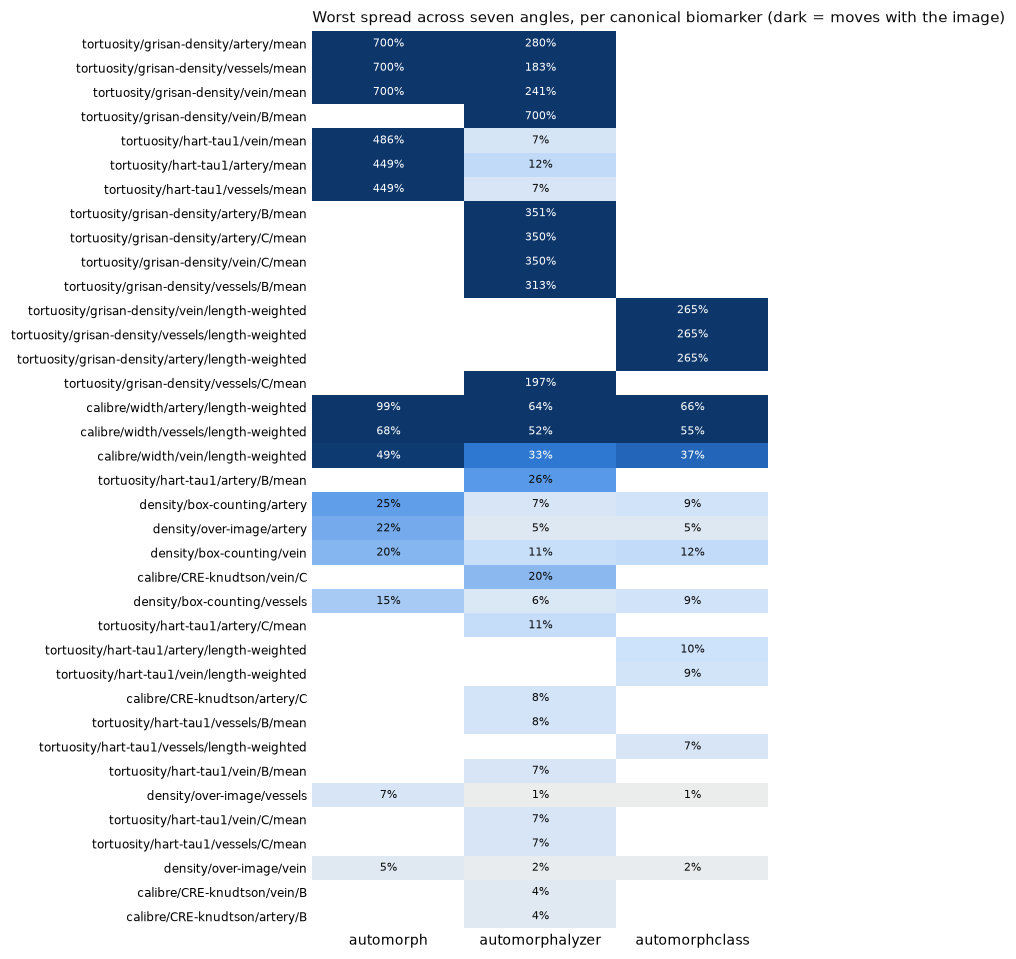

In [6]:
if len(ROTATION):
    shown = ROTATION.loc[ROTATION.max(axis=1).sort_values(ascending=False).index]
    se.heat(
        shown,
        "Worst spread across seven angles, per canonical biomarker (dark = moves with the image)",
        cap=0.5,
    )
    plt.show()

### 3.2 The columns with no canonical name

The same check on every unnamed column. Nothing can compare these with a definition, but they are
as capable of turning with the image as anything else, and nothing else would notice.

In [7]:
OWN_ROTATION = se.rotation(EVIDENCE, named=False)
if OWN_ROTATION.empty:
    print("nothing unnamed to check")
else:
    table = OWN_ROTATION.rename("worst spread").to_frame()
    moving = table[table.iloc[:, 0] > ROTATION_TOLERANCE]
    print(
        f"{len(moving)} of {len(table)} unnamed columns move by more than {ROTATION_TOLERANCE:.0%}"
    )
    display(se.legible(moving.sort_values("worst spread", ascending=False)))

12 of 20 unnamed columns move by more than 10%


worst spread
implementation  own                                              
automorph       squared_curvature_tortuosity_artery        697.2%
                squared_curvature_tortuosity_binary        694.5%
                squared_curvature_tortuosity_vein          684.7%
automorphclass  squared_curvature_tortuosity_artery        285.1%
                squared_curvature_tortuosity_vessels       282.3%
                squared_curvature_tortuosity_vein          279.9%
automorphalyzer average_local_calibre@whole_vein            27.3%
                average_local_calibre@whole_binary          13.0%
                average_local_calibre@whole_artery          10.8%
                average_local_calibre@C_artery              10.7%
                average_local_calibre@B_binary              10.3%
                average_local_calibre@B_artery              10.1%

## 4. Agreement with ground truth, by canonical name

Every named measurement against the value the catalogue's definition requires of that shape.

### 4.1 The worst disagreement, over every shape and angle

In [8]:
EVERYWHERE = EVIDENCE.in_order(
    AGAINST.groupby(["canonical", "implementation"])["error"].max().unstack("implementation")
)
faults = se.over(EVERYWHERE, GROUND_TRUTH_TOLERANCE)
print(
    f"{len(AGAINST):,} measurements over {AGAINST['canonical'].nunique()} canonical biomarkers; "
    f"{len(faults)} are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere. Worst:"
)
se.legible(faults.loc[faults.max(axis=1).sort_values(ascending=False).index])

5,353 measurements over 39 canonical biomarkers; 24 are out by more than 25% somewhere. Worst:


implementation,automorph,automorphalyzer,automorphclass
canonical,,,
tortuosity/grisan-density/artery/B/mean,—,"335,084×",—
tortuosity/grisan-density/vein/B/mean,—,"334,735×",—
tortuosity/grisan-density/vessels/B/mean,—,"331,336×",—
tortuosity/grisan-density/artery/C/mean,—,"203,093×",—
tortuosity/grisan-density/vein/C/mean,—,"203,091×",—
tortuosity/grisan-density/vessels/C/mean,—,"202,609×",—
tortuosity/grisan-density/artery/mean,"147,209×","171,365×",—
tortuosity/grisan-density/vein/mean,"164,587×","171,364×",—
tortuosity/grisan-density/vessels/mean,"141,331×","170,618×",—


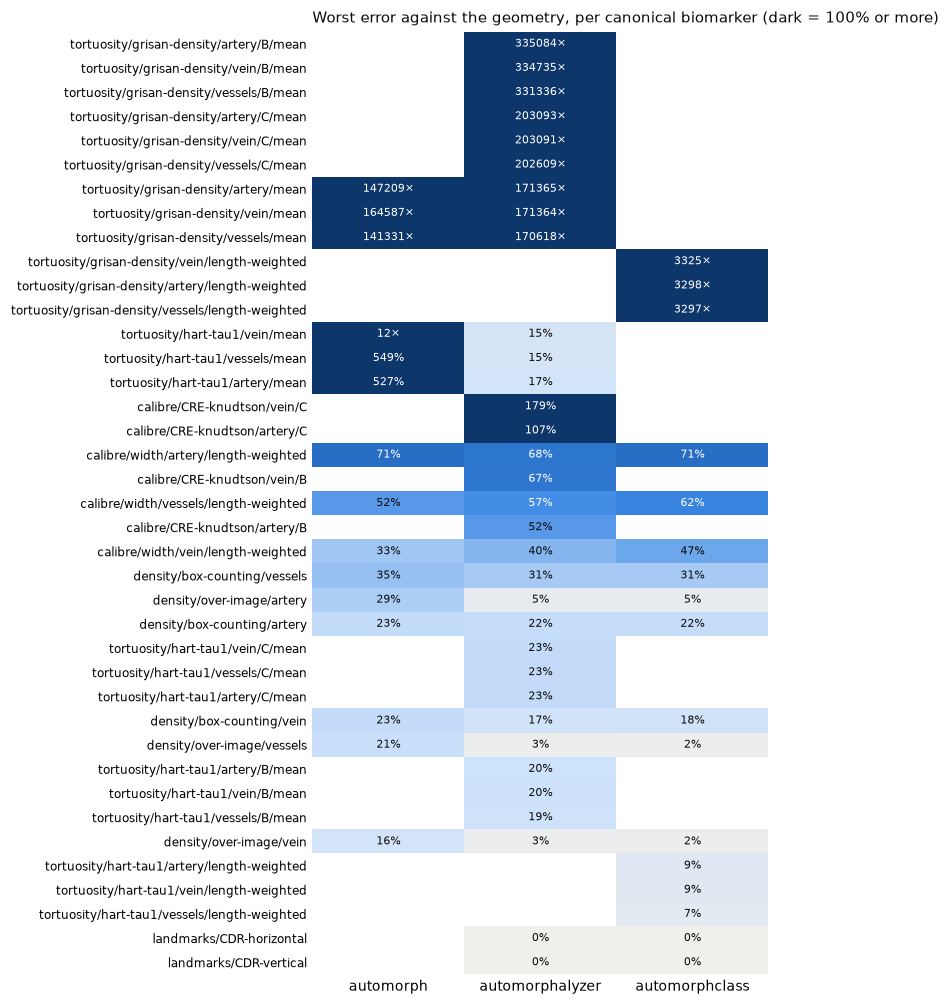

In [9]:
shown = EVERYWHERE.loc[EVERYWHERE.max(axis=1).sort_values(ascending=False).index]
se.heat(shown, "Worst error against the geometry, per canonical biomarker (dark = 100% or more)")
plt.show()

### 4.2 Where the errors fall

Every measurement of a biomarker that is out of tolerance somewhere, as one dot per shape and
angle, signed: right of the line the program said more than the geometry requires, left of it less.
The shaded band is the 25% tolerance. A tight cluster away from nought is a formula; a scatter is
the grid or the shape.

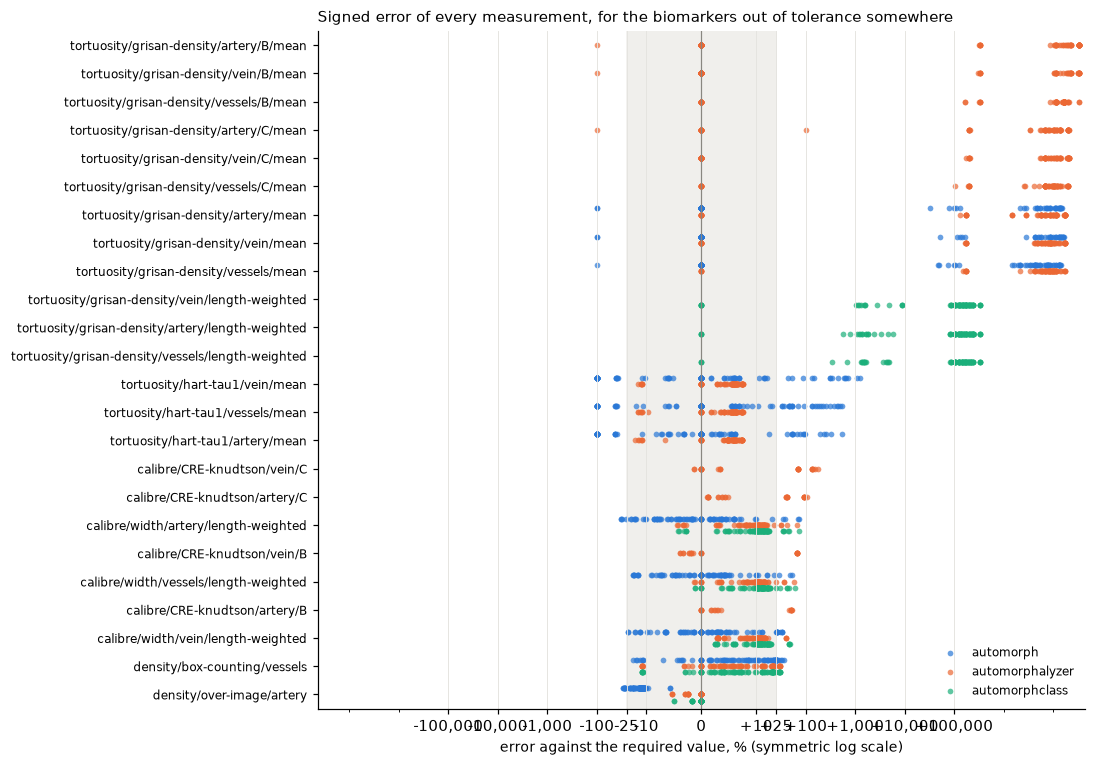

In [10]:
order = list(faults.max(axis=1).sort_values(ascending=False).index)
if order:
    se.strips(
        AGAINST[AGAINST["canonical"].isin(order)],
        order,
        IMPLEMENTATIONS,
        "Signed error of every measurement, for the biomarkers out of tolerance somewhere",
    )
    plt.show()
else:
    print("nothing is out of tolerance")

### 4.3 The same, one shape at a time

The worst over each shape's seven angles, for the biomarkers out of tolerance on that shape. A
biomarker wrong on one shape and right on the rest is a different finding from one wrong on all of
them, and §4.1 cannot tell them apart.

In [11]:
for number, shape in enumerate(EVIDENCE.shapes, start=1):
    here = AGAINST[AGAINST["shape"] == shape]
    table = se.over(
        EVIDENCE.in_order(
            here.groupby(["canonical", "implementation"])["error"].max().unstack("implementation")
        ),
        GROUND_TRUTH_TOLERANCE,
    )
    heading(f"#### 4.3.{number} {shape} — {len(table)} out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    if table.empty:
        print("every comparable biomarker lands within tolerance on this shape")
    else:
        display(se.legible(table))

#### 4.3.1 arc — 14 out by more than 25%

implementation,automorph,automorphalyzer,automorphclass
canonical,,,
tortuosity/grisan-density/artery/B/mean,—,"334,440×",—
tortuosity/grisan-density/artery/C/mean,—,"202,705×",—
tortuosity/grisan-density/artery/length-weighted,—,—,"1,692×"
tortuosity/grisan-density/artery/mean,"85,872×","170,997×",—
tortuosity/grisan-density/vein/B/mean,—,"322,563×",—
tortuosity/grisan-density/vein/C/mean,—,"202,514×",—
tortuosity/grisan-density/vein/length-weighted,—,—,"1,715×"
tortuosity/grisan-density/vein/mean,"164,587×","170,452×",—
tortuosity/grisan-density/vessels/B/mean,—,"328,501×",—


#### 4.3.2 bifurcation — 15 out by more than 25%

implementation,automorph,automorphalyzer,automorphclass
canonical,,,
tortuosity/grisan-density/artery/B/mean,—,"335,084×",—
tortuosity/grisan-density/artery/C/mean,—,"201,184×",—
tortuosity/grisan-density/artery/length-weighted,—,—,"2,205×"
tortuosity/grisan-density/artery/mean,"143,119×","170,167×",—
tortuosity/grisan-density/vein/B/mean,—,"328,268×",—
tortuosity/grisan-density/vein/C/mean,—,"133,569×",—
tortuosity/grisan-density/vein/length-weighted,—,—,"2,158×"
tortuosity/grisan-density/vein/mean,"146,923×","113,202×",—
tortuosity/grisan-density/vessels/B/mean,—,"331,336×",—


#### 4.3.3 clothoid — 15 out by more than 25%

implementation,automorph,automorphalyzer,automorphclass
canonical,,,
tortuosity/grisan-density/artery/B/mean,—,"334,823×",—
tortuosity/grisan-density/artery/C/mean,—,"202,477×",—
tortuosity/grisan-density/artery/length-weighted,—,—,"1,807×"
tortuosity/grisan-density/artery/mean,"147,209×","171,008×",—
tortuosity/grisan-density/vein/B/mean,—,"334,735×",—
tortuosity/grisan-density/vein/C/mean,—,"202,105×",—
tortuosity/grisan-density/vein/length-weighted,—,—,"1,709×"
tortuosity/grisan-density/vein/mean,"158,532×","169,769×",—
tortuosity/grisan-density/vessels/B/mean,—,"167,412×",—


... (16 outputs left out)

#### 4.3.12 straight — 19 out by more than 25%

implementation,automorph,automorphalyzer,automorphclass
canonical,,,
calibre/width/artery/length-weighted,33.2%,32.0%,36.3%
calibre/width/vein/length-weighted,32.7%,40.3%,45.3%
calibre/width/vessels/length-weighted,16.8%,36.9%,41.7%
density/over-image/artery,29.0%,0.0%,0.0%
tortuosity/grisan-density/artery/B/mean,—,"334,642×",—
tortuosity/grisan-density/artery/C/mean,—,"203,093×",—
tortuosity/grisan-density/artery/length-weighted,—,—,"3,268×"
tortuosity/grisan-density/artery/mean,0.0%,"171,365×",—
tortuosity/grisan-density/vein/B/mean,—,"334,610×",—


#### 4.3.13 tree — 17 out by more than 25%

implementation,automorph,automorphalyzer,automorphclass
canonical,,,
calibre/CRE-knudtson/artery/C,—,42.5%,—
calibre/CRE-knudtson/vein/C,—,70.8%,—
tortuosity/grisan-density/artery/B/mean,—,"219,302×",—
tortuosity/grisan-density/artery/C/mean,—,"143,159×",—
tortuosity/grisan-density/artery/length-weighted,—,—,"2,267×"
tortuosity/grisan-density/artery/mean,"137,261×","121,002×",—
tortuosity/grisan-density/vein/B/mean,—,"219,302×",—
tortuosity/grisan-density/vein/C/mean,—,"143,147×",—
tortuosity/grisan-density/vein/length-weighted,—,—,"2,262×"


### 4.4 By how the ground truth is known

A fault against an `exact` value is a fault. One against a `convention` is a question about the
definition, against an `asymptotic` value a question about how far a finite raster can go, and
against a `numerical` one a question about a 20 µm grid. They are counted apart, never pooled.

In [12]:
by_kind = (
    AGAINST.assign(out=AGAINST["error"] > GROUND_TRUTH_TOLERANCE)
    .groupby(["kind", "implementation"])["out"]
    .agg(lambda out: f"{int(out.sum())} / {len(out)}")
    .unstack("implementation")
)
EVIDENCE.in_order(by_kind)

implementation,automorph,automorphalyzer,automorphclass
kind,,,
asymptotic,11 / 273,7 / 252,8 / 273
convention,NaN,28 / 28,NaN
exact,282 / 1071,560 / 2203,254 / 1253


### 4.5 Where the geometry gives no value

A biomarker a shape settles as having **none**: no junction to take an angle at, no vessel in
zone C, no whole vessel where nothing reaches the disc. Declining there is the right answer, and a
number is invented. Each cell is how many times a number came back, out of how many it was asked.

In [13]:
INVENTED = se.invented(EVIDENCE)
if INVENTED.empty:
    print("no named column was asked about a value the geometry leaves undefined")
else:
    asked = INVENTED.groupby(["canonical", "implementation"])["invented"]
    table = EVIDENCE.in_order(
        (asked.sum().astype(int).astype(str) + " / " + asked.size().astype(str)).unstack(
            "implementation"
        )
    )
    answered = INVENTED.groupby("canonical")["invented"].any()
    print(
        f"{int(INVENTED['invented'].sum())} numbers invented out of {len(INVENTED)} chances; "
        f"the biomarkers somebody answered:"
    )
    display(table.loc[answered[answered].index] if answered.any() else table.head(0))

0 numbers invented out of 112 chances; the biomarkers somebody answered:


implementation,automorphalyzer
canonical,


## 5. Agreement with their own description

The columns the catalogue cannot name, each against what **its own authors** say it computes (§1.1).
Where that claim is a quantity the catalogue does name — Hart's squared curvature, say, which a
column is named after but does not compute — the claim's value is that biomarker's ground truth;
otherwise it is derived from the geometry. This is the claim-against-observation comparison the
atlas asks every catalogued project for, made on numbers.

In [14]:
if CLAIMED.empty:
    print("no column of this group is held to a description of its own")
else:
    OWN = (
        CLAIMED.groupby(["implementation", "own"])
        .agg(
            claims=("claims", "first"),
            held_to=("as", "first"),
            worst=("error", "max"),
            median=("error", "median"),
            renderings=("error", "size"),
        )
        .sort_values("worst", ascending=False)
    )
    print(
        f"{len(OWN)} columns held to their own description; {int((OWN['worst'] > GROUND_TRUTH_TOLERANCE).sum())} "
        f"are out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere (worst and median):"
    )
    display(OWN.assign(worst=OWN["worst"].map(se.readable), median=OWN["median"].map(se.readable)))

26 columns held to their own description; 6 are out by more than 25% somewhere (worst and median):


claims                                       held_to  \
implementation  own                                                                                                                                                                             
automorphclass  squared_curvature_tortuosity_vein                Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are     tortuosity/hart-tau3/vein/length-weighted   
                squared_curvature_tortuosity_vessels             Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are  tortuosity/hart-tau3/vessels/length-weighted   
                squared_curvature_tortuosity_artery              Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are   tortuosity/hart-tau3/artery/length-weighted   
automorph       squared_curvature_tortuosity_vein                Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are                tortuosity/hart-tau3/vein/mean   
                squared_curvature_tortuosity_binary              Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are             tortuosity/hart-tau3/vessels/mean   
                squared_curvature_tortuosity_artery              Hart's squared-curvature tortuosity, ∫κ² ds, pooled as its sibling columns are              tortuosity/hart-tau3/artery/mean   
automorphalyzer average_local_calibre@whole_vein                                        the mean local width of the vessels, sampled along them            calibre/width/vein/length-weighted   
                average_local_calibre@B_binary                                          the mean local width of the vessels, sampled along them       calibre/width/vessels/B/length-weighted   
                average_local_calibre@whole_binary                                      the mean local width of the vessels, sampled along them         calibre/width/vessels/length-weighted   
                average_local_calibre@whole_artery                                      the mean local width of the vessels, sampled along them          calibre/width/artery/length-weighted   
                average_local_calibre@C_binary                                          the mean local width of the vessels, sampled along them       calibre/width/vessels/C/length-weighted   
                average_local_calibre@C_artery                                          the mean local width of the vessels, sampled along them        calibre/width/artery/C/length-weighted   
                average_local_calibre@B_artery                                          the mean local width of the vessels, sampled along them        calibre/width/artery/B/length-weighted   
                average_local_calibre@C_vein                                            the mean local width of the vessels, sampled along them          calibre/width/vein/C/length-weighted   
                average_local_calibre@B_vein                                            the mean local width of the vessels, sampled along them          calibre/width/vein/B/length-weighted   
automorphclass  cup_height                                                                                          the cup's vertical diameter                     derived from the geometry   
automorphalyzer cup_width                                                                                         the cup's horizontal diameter                     derived from the geometry   
                cup_height                                                                                          the cup's vertical diameter                     derived from the geometry   
automorphclass  cup_width                                                                                         the cup's horizontal diameter                     derived from the geometry   
automorphalyzer disc_height                                                         

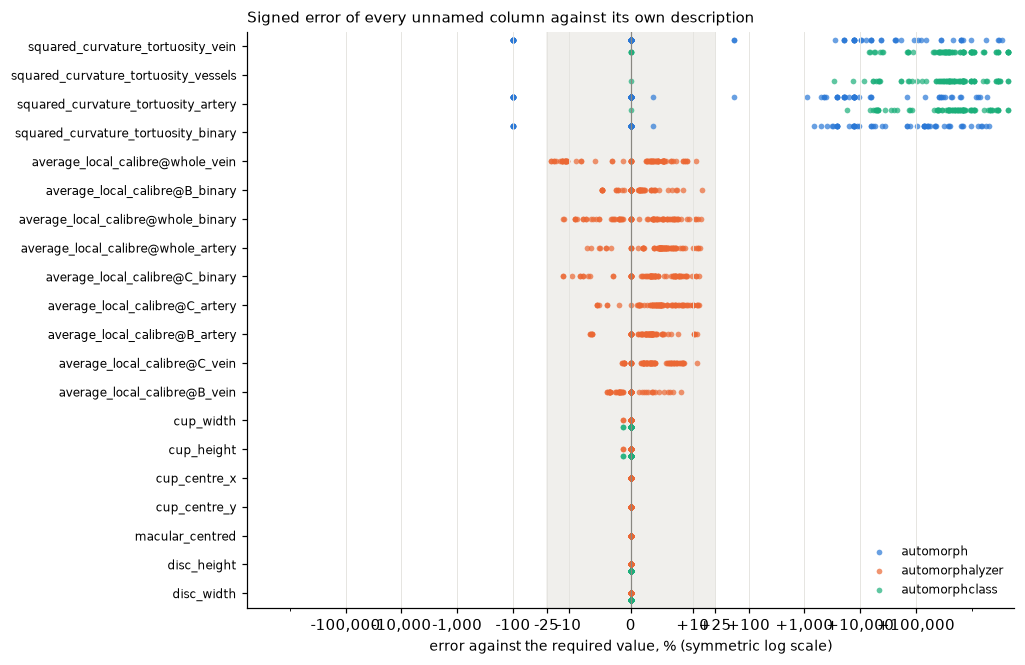

In [15]:
if not CLAIMED.empty:
    order = list(
        CLAIMED.groupby("own")["error"].max().sort_values(ascending=False).index
    )
    se.strips(
        CLAIMED,
        order,
        IMPLEMENTATIONS,
        "Signed error of every unnamed column against its own description",
        index="own",
    )
    plt.show()

## 6. The cup-to-disc ratios

The synthetic cup is an ellipse on the disc's centre whose horizontal and
vertical diameters are 0.40 and 0.55 of the disc's. A **vertical** cup-to-disc ratio is read along
the image's columns, so turning the photograph moves it, by an amount the geometry gives exactly:
at 90° the vertical and horizontal ratios have swapped. The line is what the geometry requires at
each angle; the dots are what each implementation said. AutoMorph itself is absent: its ratios are
computed in a driver that reads its own result files, which no adapter may write.

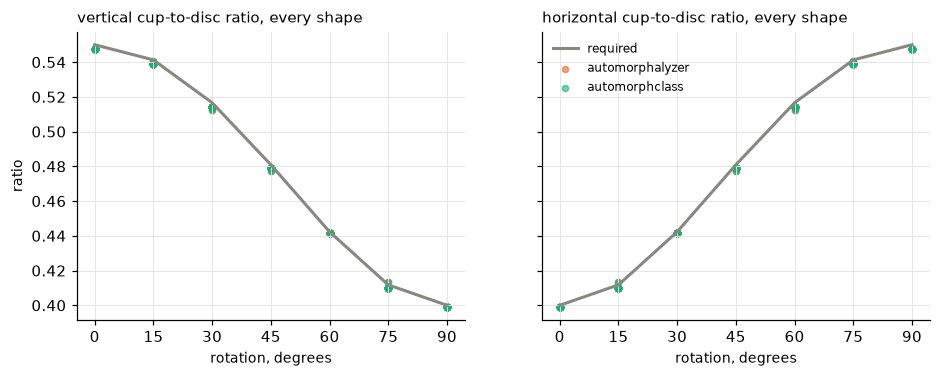

median error worst error
canonical                implementation                          
landmarks/CDR-horizontal automorphalyzer         0.0%        0.0%
                         automorphclass          0.0%        0.0%
landmarks/CDR-vertical   automorphalyzer         0.0%        0.0%
                         automorphclass          0.0%        0.0%

In [16]:
ratios = AGAINST[AGAINST["canonical"].str.startswith("landmarks/CDR")]
if ratios.empty:
    print("no implementation in this group answered a cup-to-disc ratio")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    for ax, which in zip(axes, ("vertical", "horizontal"), strict=True):
        name = f"landmarks/CDR-{which}"
        here = ratios[ratios["canonical"] == name]
        required = here.groupby("rotation")["truth"].first()
        ax.plot(required.index, required.values, color="#898781", linewidth=2, label="required")
        for colour, slug in zip(se.COLOURS, IMPLEMENTATIONS, strict=False):
            mine = here[here["implementation"] == slug]
            if mine.empty:
                continue
            ax.scatter(mine["rotation"], mine["value"], s=16, color=colour, alpha=0.6, label=slug)
        ax.set_title(f"{which} cup-to-disc ratio, every shape", fontsize=10, loc="left")
        ax.set_xlabel("rotation, degrees", fontsize=9)
        ax.set_xticks(sorted(here["rotation"].unique()))
        ax.grid(color="#e4e3df", linewidth=0.6)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    axes[0].set_ylabel("ratio", fontsize=9)
    axes[1].legend(fontsize=8, frameon=False)
    plt.show()
    display(
        se.legible(
            ratios.groupby(["canonical", "implementation"])["error"]
            .agg(["median", "max"])
            .rename(columns={"median": "median error", "max": "worst error"})
        )
    )

## 7. The best and the worst biomarkers in this group

For each implementation, its catalogued biomarkers ordered by how close they came to the geometry,
judged by their **worst** case over every shape and angle, then by their median. *Best* lists every
biomarker inside the noise floor everywhere, and at least the closest few besides (never more than
half of what it answers). *Worst* lists, of the biomarkers out by more than 25% somewhere, the five
furthest, with the shape and angle where each was furthest.

This orders biomarkers within one program, not programs: it says which of an implementation's
numbers can be taken at face value on these shapes, and which cannot.

In [17]:
for number, slug in enumerate(IMPLEMENTATIONS, start=1):
    best, worst = se.best_and_worst(AGAINST, slug)
    heading(f"### 7.{number} {slug}")
    heading(f"**Best** — {len(best)} biomarker(s)")
    shown = best.copy()
    shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
    display(shown)
    heading(f"**Worst** — out by more than {GROUND_TRUTH_TOLERANCE:.0%} somewhere")
    if worst.empty:
        print(f"nothing it answers is out by more than {GROUND_TRUTH_TOLERANCE:.0%}")
    else:
        shown = worst.copy()
        shown[["worst", "median"]] = shown[["worst", "median"]].map(se.readable)
        display(shown)

### 7.1 automorph

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on
canonical,,,,
density/over-image/vein,16.3%,8.0%,91,koch 60°
density/over-image/vessels,20.8%,11.0%,91,koch 75°
density/box-counting/vein,22.6%,7.2%,91,deep-bifurcation 90°
density/box-counting/artery,23.1%,5.8%,91,koch 45°
density/over-image/artery,29.0%,13.3%,91,straight 0°


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on
canonical,,,,
tortuosity/grisan-density/vein/mean,"164,587×",0.0%,84,arc 60°
tortuosity/grisan-density/artery/mean,"147,209×",0.0%,84,clothoid 45°
tortuosity/grisan-density/vessels/mean,"141,331×","23,945×",84,bifurcation 90°
tortuosity/hart-tau1/vein/mean,12×,11.5%,91,sinusoid 90°
tortuosity/hart-tau1/vessels/mean,548.9%,16.5%,91,clothoid 30°


### 7.2 automorphalyzer

... (5 outputs left out)

**Best** — 5 biomarker(s)

,worst,median,renderings,worst on
canonical,,,,
landmarks/CDR-horizontal,0.0%,0.0%,91,arc 0°
landmarks/CDR-vertical,0.0%,0.0%,91,arc 0°
density/over-image/vein,1.7%,0.0%,91,spokes-disc-centred 0°
density/over-image/vessels,1.7%,0.0%,91,spokes-disc-centred 0°
density/over-image/artery,5.0%,0.0%,91,crossing 0°


**Worst** — out by more than 25% somewhere

,worst,median,renderings,worst on
canonical,,,,
tortuosity/grisan-density/vein/length-weighted,"3,325×","1,335×",84,crossing 15°
tortuosity/grisan-density/artery/length-weighted,"3,298×","1,347×",84,disjoint 15°
tortuosity/grisan-density/vessels/length-weighted,"3,297×","1,425×",84,straight 15°
calibre/width/artery/length-weighted,71.2%,11.4%,91,crossing 45°
calibre/width/vessels/length-weighted,61.7%,12.5%,91,crossing 45°


### 7.4 Across the group

The same question asked of the group as a whole: for each canonical biomarker some member
computes, the member that came closest and its worst error. A biomarker is the group's best when
some member measures it to within the floor; its worst when even the closest member is far.

In [18]:
closest = AGAINST.groupby(["canonical", "implementation"])["error"].max().unstack("implementation")
GROUP_TABLE = pd.DataFrame(
    {
        # Siblings that tie are named together: PVBM and OCULAR run the same code, so picking one
        # would credit it with a result that belongs to both.
        "closest member": closest.apply(
            lambda row: " = ".join(row.index[row == row.min()]), axis=1
        ),
        "its worst error": closest.min(axis=1),
        "members answering": closest.notna().sum(axis=1),
    }
).sort_values("its worst error")
heading(
    f"**{int((GROUP_TABLE['its worst error'] == 0).sum())} of {len(GROUP_TABLE)}** canonical "
    f"biomarkers are measured to within the floor by at least one member. The closest five, then the "
    f"five furthest of those out by more than {GROUND_TRUTH_TOLERANCE:.0%} even at their closest:"
)
furthest = GROUP_TABLE[GROUP_TABLE["its worst error"] > GROUND_TRUTH_TOLERANCE].tail(5).iloc[::-1]
display(
    pd.concat({"closest": GROUP_TABLE.drop(index=furthest.index).head(5), "furthest": furthest})
    .assign(**{"its worst error": lambda t: t["its worst error"].map(se.readable)})
)

**2 of 39** canonical biomarkers are measured to within the floor by at least one member. The closest five, then the five furthest of those out by more than 25% even at their closest:

closest member its worst error  members answering
         canonical                                                                                                    
closest  landmarks/CDR-horizontal                  automorphalyzer = automorphclass            0.0%                  2
         landmarks/CDR-vertical                    automorphalyzer = automorphclass            0.0%                  2
         density/over-image/vein                                     automorphclass            1.7%                  3
         density/over-image/vessels                                  automorphclass            1.7%                  3
         density/over-image/artery                                   automorphclass            5.0%                  3
furthest tortuosity/grisan-density/artery/B/mean                    automorphalyzer        335,084×                  1
         tortuosity/grisan-density/vein/B/mean                      automorphalyzer        334,735×                  1
         tortuosity/grisan-density/vessels/B/mean                   automorphalyzer        331,336×                  1
         tortuosity/grisan-density/artery/C/mean                    automorphalyzer        203,093×                  1
         tortuosity/grisan-density/vein/C/mean                      automorphalyzer        203,091×                  1

## 8. Summary

Two counts per implementation, each as a fraction so its denominator is visible. Rotation can be
checked on anything that returned a number; agreement only on what has a value to agree with, by
canonical name or by its own description.

In [19]:
EVERY_ROTATION = pd.concat([se.rotation(EVIDENCE, True), se.rotation(EVIDENCE, False)])
summary = {}
for slug in IMPLEMENTATIONS:
    steady = EVERY_ROTATION.loc[slug].dropna() if slug in EVERY_ROTATION.index.get_level_values(0) else pd.Series(dtype=float)
    named = AGAINST[AGAINST["implementation"] == slug].groupby("canonical")["error"].max()
    own = CLAIMED[CLAIMED["implementation"] == slug].groupby("own")["error"].max()
    summary[slug] = {
        "move with the image": f"{int((steady > ROTATION_TOLERANCE).sum())} / {len(steady)}",
        "disagree with the geometry (canonical)": f"{int((named > GROUND_TRUTH_TOLERANCE).sum())} / {len(named)}",
        "disagree with their own description": f"{int((own > GROUND_TRUTH_TOLERANCE).sum())} / {len(own)}",
        "median error, canonical": f"{100 * AGAINST.loc[AGAINST['implementation'] == slug, 'error'].median():.1f}%",
        "exceptions": int((TROUBLES["implementation"] == slug).sum()),
        "seconds per image": round(EVIDENCE.measured[slug]["seconds"].astype(float).mean(), 1),
    }
pd.DataFrame(summary)

,automorph,automorphalyzer,automorphclass
move with the image,16 / 18,23 / 43,10 / 20
disagree with the geometry (canonical),11 / 15,17 / 33,7 / 17
disagree with their own description,3 / 3,0 / 16,3 / 7
"median error, canonical",8.6%,6.1%,5.6%
exceptions,0,21,0
seconds per image,1.7,7.0,1.5


## 9. What this group's evidence shows

*Our reading of the tables above, on the run of 2026-11-22. Every figure is one this notebook
printed; the authors' own claims are in §1.1 and are not restated as ours.*

**The cup-to-disc ratios are the one thing this group measures exactly.** Both rewrites compute
the vertical and horizontal ratios from the disc and cup they are handed, and both land inside the
noise floor on every shape at every angle (§6) — including the swap the geometry requires as the
picture turns, from 0.55 vertically at 0° to 0.40 at 90°. AutoMorph's own ratios are computed in a
driver script that reads its result files back, which no adapter may write, so it has none here.
That is a statement about the adapters' reach, not about AutoMorph's arithmetic.

**The rewrites fixed AutoMorph's tortuosity and kept its Grisan density.** AutoMorph's Hart τ1 (arc
over chord) is out by up to 1,226% and moves by 449% when the picture turns; the rewrites are 7–26%
under rotation and 15–17% (AutoMorphalyzer) or under 10% (AutoMorphClass, length-weighted) against
the geometry. Grisan's tortuosity density is wrong in all three: on a vessel that bends one way
throughout the geometry requires nought, and AutoMorph and AutoMorphalyzer return about one per
pixel, AutoMorphClass about a fiftieth of that. It also moves by 180–700% under rotation.

**Calibre is the group's weak family.** Length-weighted vessel width is out by 33–71% in every member,
worst on `crossing`, and moves by 33–99% under rotation. Zone-B and zone-C Knudtson equivalents,
which only AutoMorphalyzer computes, are 52–179% out on `deep-bifurcation`.

**Density is the group's strong family.** Vessel area over the image is within 5.0–5.3% for both
rewrites and 29% for AutoMorph; box-counting dimension is 22–36% out, against a value no finite raster
reaches.

**Held to their own description**, AutoMorphalyzer's sixteen unnamed columns all land within 25% —
its `average_local_calibre` agrees with the length-weighted width it describes, and its disc and cup
extents with the drawn ellipses. The squared-curvature column of AutoMorph and AutoMorphClass does
not: it is named for Hart's ∫κ² ds, and returns tens to tens of thousands of times that value,
non-zero on shapes with no curvature at all. Nothing else in the catalogue checks it.

**AutoMorphalyzer raises on `disjoint`** — vessels that never reach the disc — in all three of its
measuring passes at every angle (21 exceptions). It now returns its disc and cup figures there
regardless, so those renderings count as measured rather than failed.

**Which to reach for, within this lineage:** AutoMorphClass for tortuosity and speed (1.5 s an
image), either rewrite for the cup-to-disc ratios, none of them for calibre or Grisan density.